In [1]:
%load_ext autoreload

%autoreload 2

In [3]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from bgflow.utils import (assert_numpy, distance_vectors, distances_from_vectors, 
                          remove_mean, IndexBatchIterator, LossReporter, as_numpy, compute_distances
)
from bgflow import (GaussianMCMCSampler, DiffEqFlow, BoltzmannGenerator, Energy, Sampler, 
                    MultiDoubleWellPotential, MeanFreeNormalDistribution, KernelDynamics, 
                    BlackBoxDynamics, TimeIndependentDynamics, DenseNet)
from bgflow.bg import sampling_efficiency
import ot as pot
import tqdm
from eq_ot_flow.models import EGNN_dynamics
from eq_ot_flow.utilities import superpose_points, superpose_points_batch, plot_flowpath_trajectory, plot_flowpath_trajectory_3d
from eq_ot_flow.estimator import BruteForceEstimatorFast
from eq_ot_flow.LJ import LennardJonesPotential
from scipy.optimize import linear_sum_assignment
from torchdyn.core import NeuralODE


In [6]:
# first define system dimensionality and a target energy/distribution

dim = 39
n_particles = 13
n_dimensions = dim // n_particles


target = LennardJonesPotential(dim, n_particles, eps=1., rm=1, oscillator_scale=1, two_event_dims=False)

In [7]:
data_load = np.load("data/all_data_LJ13-1000.npy", allow_pickle=True)
data = torch.from_numpy(remove_mean(data_load, n_particles, n_dimensions))


In [9]:
n_training_data = 100000
np.random.seed(0)
idx = np.random.choice(np.arange(len(data)), len(data), replace=False)
data_smaller = data[idx[:100000]]
data_holdout = data[idx[500000:]]

In [11]:
# now set up a prior
prior =  MeanFreeNormalDistribution(dim, n_particles, two_event_dims=False).cuda()
prior_cpu =  MeanFreeNormalDistribution(dim, n_particles, two_event_dims=False)

In [17]:
# Build the Boltzmann Generator

net_dynamics = EGNN_dynamics(n_particles=n_particles, device='cuda',  n_dimension=dim // n_particles, hidden_nf=32,
    act_fn=torch.nn.SiLU(), n_layers=3, recurrent=True, tanh=True, attention=True, condition_time=True, mode='egnn_dynamics', agg='sum')


bb_dynamics = BlackBoxDynamics(
    dynamics_function=net_dynamics,
    divergence_estimator=BruteForceEstimatorFast()
)
flow = DiffEqFlow(
    dynamics=bb_dynamics
)
# having a flow and a prior, we can now define a Boltzmann Generator

bg = BoltzmannGenerator(prior, flow, target).cuda()

In [19]:
# train with convex mixture of NLL and KL loss

n_batch = 256
batch_iter = IndexBatchIterator(len(data_smaller), n_batch)

optim = torch.optim.Adam(bg.parameters(), lr=1e-3)

n_epochs = 1000
n_report_steps = 5

# mixing parameter

reporter = LossReporter("NLL")
val_losses = []

In [20]:
# start at 5e-4 for 1000
# 5e-5 for 1000

## Note, in practice the batch reordering should not be done during training

In [ ]:
sigma = 0.01
for epoch in range(n_epochs):
    for it, idxs in enumerate(batch_iter):

        optim.zero_grad()
        x1 = data_smaller[idxs].cuda()
        batchsize = x1.shape[0]
        t = torch.rand(batchsize, 1).cuda()
        x0 = prior.sample(batchsize)

        # Resample x0, x1 according to transport matrix
        a1, b1 = pot.unif(x0.size()[0]), pot.unif(x1.size()[0])
        M = torch.cdist(x0, x1) ** 2
        M = M / M.max()
        pi = pot.emd(a1, b1, M.detach().cpu().numpy())
        # Sample random interpolations on pi
        p = pi.flatten()
        p = p / p.sum()
        choices = np.random.choice(pi.shape[0] * pi.shape[1], p=p, size=batchsize)
        i, j = np.divmod(choices, pi.shape[1])
        x0 = x0[i]
        x1 = x1[j]
        # calculate regression loss
        mu_t = x0 * (1 - t) + x1 * t
        sigma_t = sigma
        noise = prior.sample(batchsize)
        x = mu_t + sigma_t * noise
        ut = x1 - x0
        vt = bg.flow._dynamics._dynamics._dynamics_function(t, x)
        loss = torch.mean((vt - ut) ** 2)
        loss.backward()
        optim.step()
        reporter.report(loss)

        if it % n_report_steps == 0:
            print("\repoch: {0}, iter: {1}/{2}, loss: {3:.4}".format(
                    epoch,
                    it,
                    len(batch_iter),
                    *reporter.recent(1).ravel()
                ), end="")

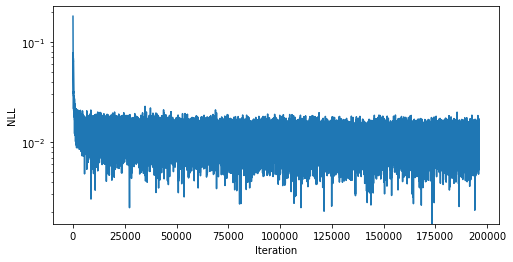

In [28]:
reporter.plot(log=True)

In [ ]:
# load a model
# eq OT flow matching
# PATH = "models/LJ13_eq_OT_flow_matching"
# checkpoint = torch.load(PATH)
# flow.load_state_dict(checkpoint['model_state_dict']), optim.load_state_dict(checkpoint['optimizer_state_dict'])
# OT flow matching
# PATH = "models/LJ13_OT_flow_matching"
# bg.load_state_dict(torch.load(PATH))

In [ ]:
# samples with or without weights

sample_with_dlogp = True

node = NeuralODE(
   net_dynamics, solver="dopri5", sensitivity="adjoint", atol=1e-4, rtol=1e-4
)

bg.flow._integrator_atol = 1e-5
bg.flow._integrator_rtol = 1e-5
flow._use_checkpoints = False
flow._kwargs = {}

n_samples = 200
n_sample_batches = 50
latent_np = np.empty(shape=(0))
samples_np = np.empty(shape=(0))
log_w_np = np.empty(shape=(0))

energies_np = np.empty(shape=(0))
distances_x_np = np.empty(shape=(0))

if sample_with_dlogp:
    for i in tqdm.tqdm(range(n_sample_batches)):
        with torch.no_grad():
            samples, latent, dlogp = bg.sample(n_samples, with_latent=True, with_dlogp=True)
            #latent = latent[0]
            log_weights = bg.log_weights_given_latent(samples, latent, dlogp, normalize=False).detach().cpu().numpy()
            latent_np = np.append(latent_np, latent.detach().cpu().numpy())
            samples_np = np.append(samples_np, samples.detach().cpu().numpy())
            distances_x = distances_from_vectors(distance_vectors(samples.view(-1, n_particles, n_dimensions))).detach().cpu().numpy().reshape(-1)
            distances_x_np = np.append(distances_x_np, distances_x)

            log_w_np = np.append(log_w_np, log_weights)
            energies = target.energy(samples).detach().cpu().numpy()
            energies_np = np.append(energies_np, energies)

else:
    for i in tqdm.tqdm(range(n_sample_batches)):
        with torch.no_grad():
            traj = node.trajectory(
                prior.sample(n_samples),
                t_span=torch.linspace(0, 1, 2),
            )
            latent = traj[0].reshape(-1, dim)
            samples = traj[-1].reshape(-1, dim)

            #latent = latent[0]
            #log_weights = bg.log_weights_given_latent(samples, latent, dlogp).detach().cpu().numpy()
            latent_np = np.append(latent_np, latent.detach().cpu().numpy())
            samples_np = np.append(samples_np, samples.detach().cpu().numpy())
            distances_x = distances_from_vectors(distance_vectors(samples.view(-1, n_particles, n_dimensions))).detach().cpu().numpy().reshape(-1)
            distances_x_np = np.append(distances_x_np, distances_x)

            energies = target.energy(samples).detach().cpu().numpy()
            energies_np = np.append(energies_np, energies)


latent_np = latent_np.reshape(-1, dim)
samples_np = samples_np.reshape(-1, dim)


In [ ]:
sampling_efficiency(torch.from_numpy(log_w_np)).item()

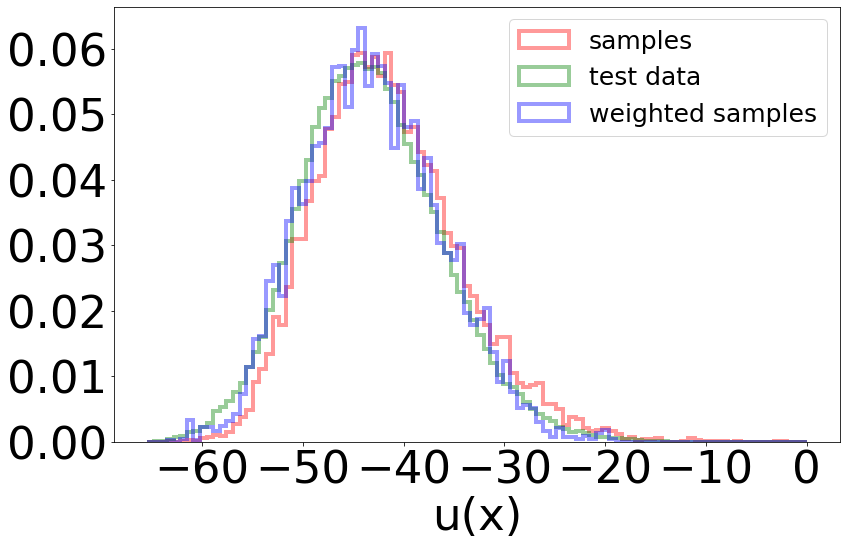

In [57]:
energies_data = target.energy(data_holdout).numpy()
energies_bg = energies_np
energies_prior = target.energy(latent).cpu().detach().numpy()
min_energy = min(energies_data.min(), energies_bg.min())
max_energy = max(energies_data.max(), energies_bg.max())

plt.figure(figsize=(13,8))
efac = 1

plt.hist(energies_bg, bins=100, density=True,  range=(min_energy, 0), alpha=0.4, histtype='step', linewidth=4,
         color="r", label="samples");

plt.hist(energies_data, bins=100, density=True, range=(min_energy, 0), alpha=0.4, color="g", histtype='step', linewidth=4, 
         label="test data");
plt.hist(energies_bg, bins=100, density=True,  range=(min_energy, 0), alpha=0.4, histtype='step', linewidth=4,
         color="b", label="weighted samples", weights=np.exp(log_w_np));


plt.xlabel("u(x)", fontsize=45)  
plt.xticks(fontsize=45) 
plt.yticks(fontsize=45);
plt.legend(fontsize=25);

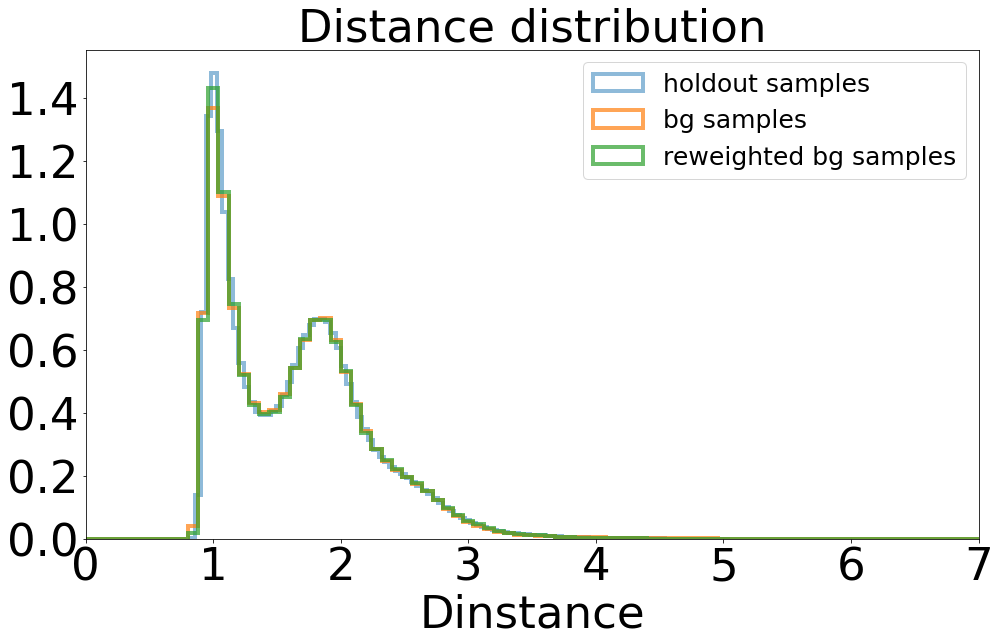

In [59]:
dists = distances_from_vectors(
            distance_vectors(data_holdout.view(-1, n_particles, dim // n_particles)))
dists_prior = distances_from_vectors(
            distance_vectors(latent.view(-1, n_particles, dim // n_particles)))

plt.figure(figsize=(16,9))
plt.hist(as_numpy(dists.view(-1)), bins=100, label="holdout samples", alpha=0.5, density=True, histtype='step', linewidth=4);
plt.hist(distances_x_np, bins=100, label="bg samples", alpha=0.7, density=True, histtype='step', linewidth=4, range=(0,8));
plt.hist(distances_x_np, bins=100, label="reweighted bg samples", alpha=0.7, density=True, histtype='step',
         linewidth=4, weights=np.repeat(np.exp(log_w_np).flatten(), n_particles*(n_particles-1)), range=(0,8));
plt.xlim(0,7)
plt.legend(fontsize=25)
plt.xlabel("Dinstance", fontsize=45)  
plt.xticks(fontsize=45) 
plt.yticks(fontsize=45);
plt.title("Distance distribution", fontsize=45);


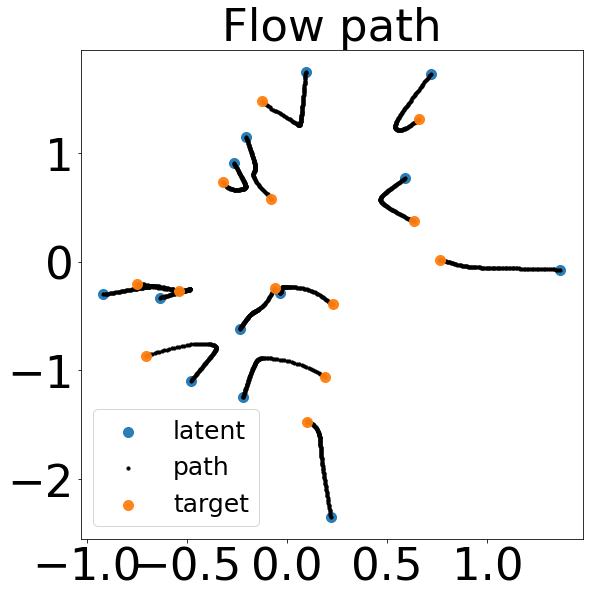

In [22]:
node = NeuralODE(
   net_dynamics, solver="dopri5", sensitivity="adjoint", atol=1e-4, rtol=1e-4
)

with torch.no_grad():
    traj = node.trajectory(
        prior.sample(10000),
        t_span=torch.linspace(0, 1, 100),
    )
plot_flowpath_trajectory(traj[:, 0].reshape(-1, n_particles, n_dimensions)[:,:, :2])

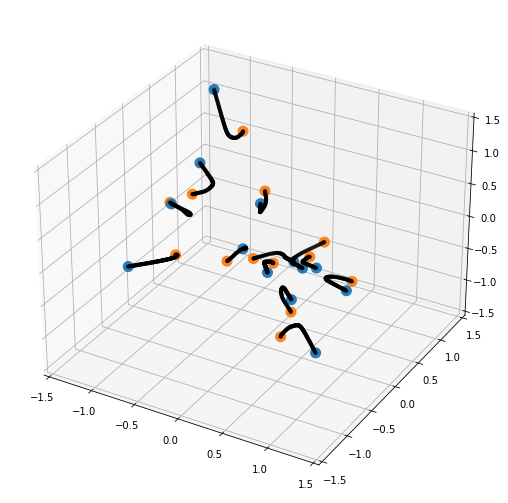

In [37]:
plot_flowpath_trajectory_3d(traj[:,12].reshape(-1, n_particles, n_dimensions))

RESULT MIGHT BE INACURATE
Max number of iteration reached, currently 100000. Sometimes iterations go on in cycle even though the solution has been reached, to check if it's the case here have a look at the minimal reduced cost. If it is very close to machine precision, you might actually have the correct solution, if not try setting the maximum number of iterations a bit higher


(2.8239925, 2.0575497)

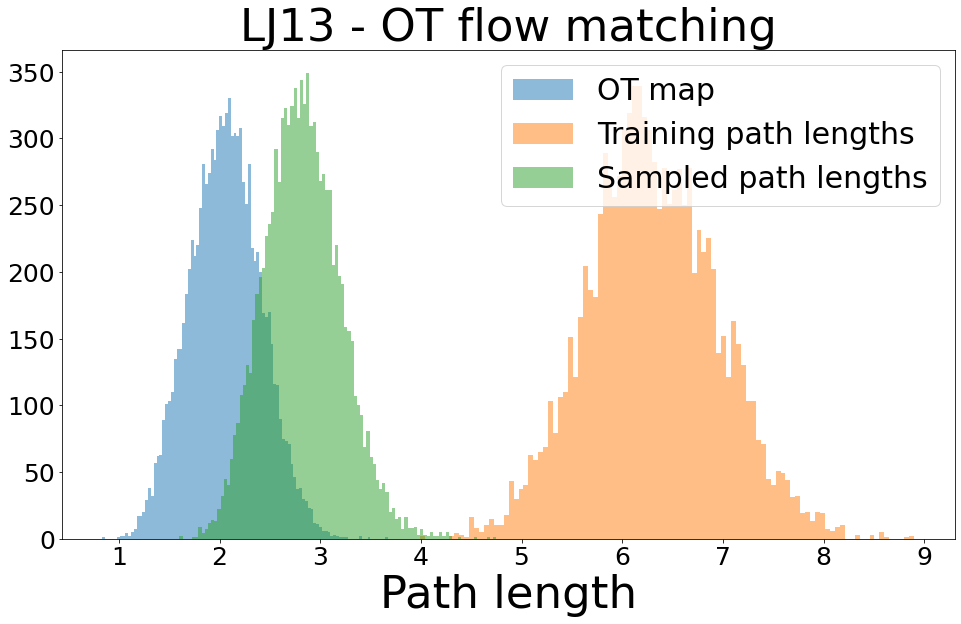

In [24]:
path_lengths = torch.linalg.norm(traj[1:]-traj[:-1], dim=-1).sum(0) #/ len(t_span)
ot_path_lengths = []
for i in range(len(traj[-1])):
    # define two sets of points
    points1 = traj[0, i].reshape(n_particles, n_dimensions).cpu()
    points2 = traj[-1, i].reshape(n_particles, n_dimensions).cpu()

    # compute pairwise distances between the two sets of points
    distances = torch.cdist(points1, points2)

    # use the Hungarian algorithm to solve the assignment problem
    row_idx, col_idx = linear_sum_assignment(distances**2)
    # reorder the second set of points according to the optimal assignment
    points2 = superpose_points(points2[col_idx], points1).flatten()
    # reorder the second set of points according to the optimal assignment
    ot_path_lengths.append(np.linalg.norm(points2-points1.flatten()))
ot_path_lengths = np.array(ot_path_lengths)

x1 = data[:len(traj[-1])].cuda()
batchsize = x1.shape[0]
t = torch.rand(batchsize, 1).cuda()
x0 = prior.sample(batchsize)

# Resample x0, x1 according to transport matrix
a1, b1 = pot.unif(x0.size()[0]), pot.unif(x1.size()[0])
M = torch.cdist(x0, x1) ** 2
M = M / M.max()
pi = pot.emd(a1, b1, M.detach().cpu().numpy())
# Sample random interpolations on pi
p = pi.flatten()
p = p / p.sum()
choices = np.random.choice(pi.shape[0] * pi.shape[1], p=p, size=batchsize)
i, j = np.divmod(choices, pi.shape[1])
x0 = x0[i]
x1 = x1[j]
training_path_lengths = as_numpy(torch.linalg.norm(x1-x0, dim=-1))


plt.figure(figsize=(16,9))
plt.hist(as_numpy(ot_path_lengths), bins=100, alpha=0.5, label="OT map", density=True);
plt.hist(as_numpy(training_path_lengths), bins=100, alpha=0.5,label="Training path lengths", density=True);
plt.hist(as_numpy(path_lengths), bins=100, alpha=0.5,label="Sampled path lengths", density=True);

plt.xlabel("Path length", fontsize=45)  
plt.title(f"LJ13 - OT flow matching", fontsize=45)
plt.legend(fontsize=30)
plt.xticks(fontsize=25) 
plt.yticks(fontsize=25);
as_numpy(path_lengths).mean(), as_numpy(ot_path_lengths).mean()

In [ ]:
import tqdm
data_holdout = data_holdout
batch_size=50
spacing = 100
n = len(data_holdout) // batch_size // spacing
nll = 0

for i in tqdm.tqdm(range(n)):
    batch = data_holdout[::spacing][i*batch_size:i*batch_size+ batch_size].cuda()
    with torch.no_grad():
        nll += bg.energy(batch).mean() / n

nll

In [ ]:
nll

In [ ]:
import tqdm
batch_size=50
spacing = 30
n = len(data_smaller) // batch_size// spacing
nll_data_smaller = 0

for i in tqdm.tqdm(range(n)):
    batch = data_smaller[::spacing][i*batch_size:i*batch_size+ batch_size].cuda()
    with torch.no_grad():
        nll_data_smaller += bg.energy(batch).mean() / n

nll_data_smaller

In [ ]:
nll_data_smaller